In [5]:
from google.colab import drive
drive.mount('/content/drive')

import json
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras.applications.densenet import preprocess_input  # DenseNet121 đã chọn

# ---- Cấu hình đường dẫn (đúng cấu trúc thư mục thật trong Drive) ----
BASE_DIR     = "/content/drive/MyDrive/flower-multilabel-project"
MODEL_PATH   = f"{BASE_DIR}/models/final/flower_multilabel_model.keras"
CLASSES_PATH = f"{BASE_DIR}/data/metadata/classes.json"
TEST_DIR     = f"{BASE_DIR}/data/splits/test"        # KHÔNG có "/images"
TEST_LABELS  = f"{BASE_DIR}/data/splits/test/labels.csv"
IMG_SIZE     = (224, 224)
BATCH_SIZE   = 32

# ---- Load danh sách 10 lớp, đúng thứ tự cố định trong classes.json ----
with open(CLASSES_PATH, "r", encoding="utf-8") as f:
    classes_info = json.load(f)
class_ids = [c["id"] for c in classes_info]
print("Số lớp:", len(class_ids), class_ids)

# ---- Load model DenseNet121 đã chọn ----
model = tf.keras.models.load_model(MODEL_PATH)

# ---- Load nhãn test ----
df_test = pd.read_csv(TEST_LABELS)
y_true = df_test[class_ids].values.astype("float32")
filenames = df_test["filename"].values
print("Số ảnh test:", len(df_test))

# ---- Đọc & tiền xử lý ảnh, dùng đúng preprocess_input đã dùng lúc train (mục 4a blueprint) ----
def load_and_preprocess(path):
    img = tf.io.read_file(path)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, IMG_SIZE)
    img = preprocess_input(img)
    return img

full_paths = [f"{TEST_DIR}/{fn}" for fn in filenames]
ds = tf.data.Dataset.from_tensor_slices(full_paths)
ds = ds.map(load_and_preprocess, num_parallel_calls=tf.data.AUTOTUNE)
ds = ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

# ---- Dự đoán xác suất sigmoid cho toàn bộ tập test (chưa áp ngưỡng) ----
y_pred_proba = model.predict(ds, verbose=1)   # shape kỳ vọng: (900, 10)

print("y_true shape:", y_true.shape)
print("y_pred_proba shape:", y_pred_proba.shape)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Số lớp: 10 ['hoa_hong', 'hoa_huong_duong', 'hoa_cuc', 'hoa_tulip', 'hoa_bo_cong_anh', 'hoa_sen', 'hoa_lan', 'hoa_mai', 'hoa_dao', 'hoa_oai_huong']
Số ảnh test: 900
29/29 ━━━━━━━━━━━━━━━━━━━━ 183s 5s/step
y_true shape: (900, 10)
y_pred_proba shape: (900, 10)


In [9]:
# ---- Sửa lại hàm tiền xử lý: KHÔNG gọi preprocess_input nữa, model đã tự làm bên trong ----
def load_and_preprocess(path):
    img = tf.io.read_file(path)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, IMG_SIZE)
    img = tf.cast(img, tf.float32)   # giữ nguyên [0, 255], KHÔNG chia 255, KHÔNG trừ mean
    return img

# ---- Build lại dataset và predict lại ----
full_paths = [f"{TEST_DIR}/{fn}" for fn in filenames]
ds = tf.data.Dataset.from_tensor_slices(full_paths)
ds = ds.map(load_and_preprocess, num_parallel_calls=tf.data.AUTOTUNE)
ds = ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

y_pred_proba = model.predict(ds, verbose=1)

print("y_true shape:", y_true.shape)
print("y_pred_proba shape:", y_pred_proba.shape)
print("mean proba:", y_pred_proba.mean())
print("Số giá trị > 0.5:", (y_pred_proba > 0.5).sum(), "/", y_pred_proba.size)

29/29 ━━━━━━━━━━━━━━━━━━━━ 144s 5s/step
y_true shape: (900, 10)
y_pred_proba shape: (900, 10)
mean proba: 0.19029586
Số giá trị > 0.5: 1617 / 9000


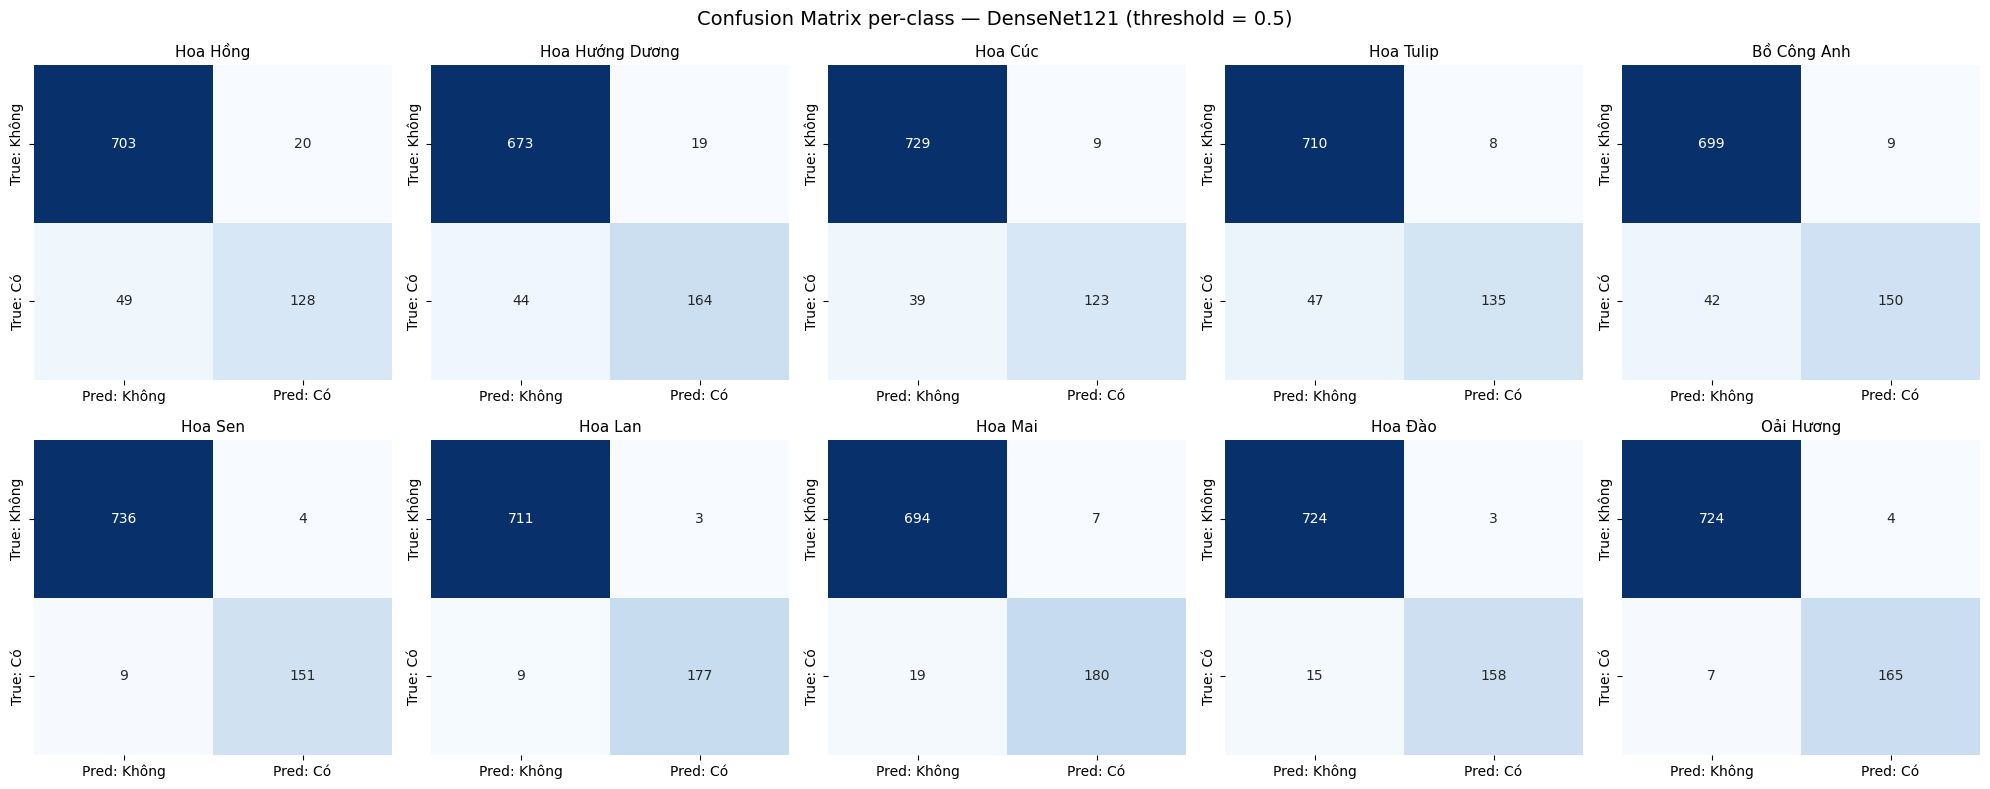

Đã lưu confusion matrix tại: /content/drive/MyDrive/flower-multilabel-project/reports/weekly_progress/tuan3_confusion_matrix.png
            Lớp  TN  FP  FN  TP
       Hoa Hồng 703  20  49 128
Hoa Hướng Dương 673  19  44 164
        Hoa Cúc 729   9  39 123
      Hoa Tulip 710   8  47 135
    Bồ Công Anh 699   9  42 150
        Hoa Sen 736   4   9 151
        Hoa Lan 711   3   9 177
        Hoa Mai 694   7  19 180
        Hoa Đào 724   3  15 158
      Oải Hương 724   4   7 165


In [10]:
from sklearn.metrics import multilabel_confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

THRESHOLD_DEFAULT = 0.5
y_pred_binary = (y_pred_proba >= THRESHOLD_DEFAULT).astype(int)

# ---- Multilabel confusion matrix: ra 10 ma trận 2x2, mỗi lớp 1 ma trận (TN, FP, FN, TP) ----
mcm = multilabel_confusion_matrix(y_true, y_pred_binary)   # shape: (10, 2, 2)

# ---- Tên hiển thị tiếng Việt lấy từ classes.json ----
class_names = [c["name"] for c in classes_info]   # đổi key "name" nếu classes.json đặt tên khác

# ---- Vẽ lưới 10 heatmap (2 hàng x 5 cột) ----
fig, axes = plt.subplots(2, 5, figsize=(20, 8))
axes = axes.flatten()

for i, (cm, name) in enumerate(zip(mcm, class_names)):
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues", cbar=False,
        xticklabels=["Pred: Không", "Pred: Có"],
        yticklabels=["True: Không", "True: Có"],
        ax=axes[i]
    )
    axes[i].set_title(name, fontsize=11)

plt.suptitle(f"Confusion Matrix per-class — DenseNet121 (threshold = {THRESHOLD_DEFAULT})", fontsize=14)
plt.tight_layout()

# ---- Lưu file để chèn vào báo cáo (đặt cùng kiểu tên với tuan3_loss_curves.png đã có) ----
SAVE_PATH = f"{BASE_DIR}/reports/weekly_progress/tuan3_confusion_matrix.png"
plt.savefig(SAVE_PATH, dpi=150, bbox_inches="tight")
plt.show()

print(f"Đã lưu confusion matrix tại: {SAVE_PATH}")

# ---- In thêm bảng số liệu tóm tắt TP/FP/FN/TN từng lớp để đối chiếu ----
summary_rows = []
for i, name in enumerate(class_names):
    tn, fp, fn, tp = mcm[i].ravel()
    summary_rows.append({"Lớp": name, "TN": tn, "FP": fp, "FN": fn, "TP": tp})

df_cm_summary = pd.DataFrame(summary_rows)
print(df_cm_summary.to_string(index=False))

In [11]:
from sklearn.metrics import precision_recall_fscore_support, classification_report

# ---- Precision/Recall/F1 riêng từng lớp, threshold 0.5 (baseline hiện tại) ----
precision, recall, f1, support = precision_recall_fscore_support(
    y_true, y_pred_binary, average=None, zero_division=0
)

df_per_class = pd.DataFrame({
    "Lớp": class_names,
    "ID": class_ids,
    "Precision": precision.round(4),
    "Recall": recall.round(4),
    "F1-score": f1.round(4),
    "Support (số ảnh có nhãn này)": support
})

print(df_per_class.to_string(index=False))

# ---- Trung bình macro (không trọng số theo support — đúng kiểu SRS yêu cầu NFR-02) ----
precision_macro, recall_macro, f1_macro, _ = precision_recall_fscore_support(
    y_true, y_pred_binary, average="macro", zero_division=0
)
print(f"\nMacro-average — Precision: {precision_macro:.4f} | Recall: {recall_macro:.4f} | F1: {f1_macro:.4f}")

# ---- Lưu bảng ra CSV để đính kèm báo cáo tuần 4 ----
SAVE_CSV = f"{BASE_DIR}/reports/weekly_progress/tuan4_per_class_metrics.csv"
df_per_class.to_csv(SAVE_CSV, index=False, encoding="utf-8-sig")
print(f"\nĐã lưu: {SAVE_CSV}")

            Lớp              ID  Precision  Recall  F1-score  Support (số ảnh có nhãn này)
       Hoa Hồng        hoa_hong     0.8649  0.7232    0.7877                           177
Hoa Hướng Dương hoa_huong_duong     0.8962  0.7885    0.8389                           208
        Hoa Cúc         hoa_cuc     0.9318  0.7593    0.8367                           162
      Hoa Tulip       hoa_tulip     0.9441  0.7418    0.8308                           182
    Bồ Công Anh hoa_bo_cong_anh     0.9434  0.7812    0.8547                           192
        Hoa Sen         hoa_sen     0.9742  0.9438    0.9587                           160
        Hoa Lan         hoa_lan     0.9833  0.9516    0.9672                           186
        Hoa Mai         hoa_mai     0.9626  0.9045    0.9326                           199
        Hoa Đào         hoa_dao     0.9814  0.9133    0.9461                           173
      Oải Hương   hoa_oai_huong     0.9763  0.9593    0.9677                           172

In [12]:
# ---- Load tập validation (dùng để chọn threshold, KHÔNG dùng test — tránh data leakage) ----
VAL_DIR    = f"{BASE_DIR}/data/splits/val"
VAL_LABELS = f"{BASE_DIR}/data/splits/val/labels.csv"

df_val = pd.read_csv(VAL_LABELS)
y_val_true = df_val[class_ids].values.astype("float32")
val_filenames = df_val["filename"].values
print("Số ảnh val:", len(df_val))

val_full_paths = [f"{VAL_DIR}/{fn}" for fn in val_filenames]
ds_val = tf.data.Dataset.from_tensor_slices(val_full_paths)
ds_val = ds_val.map(load_and_preprocess, num_parallel_calls=tf.data.AUTOTUNE)  # dùng lại hàm đã sửa ở Cell 1b
ds_val = ds_val.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

y_val_pred_proba = model.predict(ds_val, verbose=1)
print("y_val_pred_proba shape:", y_val_pred_proba.shape)

# ---- Quét threshold 0.05 -> 0.95 (bước 0.05) riêng từng lớp, chọn F1 cao nhất mỗi lớp ----
from sklearn.metrics import f1_score

threshold_candidates = np.arange(0.05, 0.96, 0.05)
optimal_thresholds = {}
threshold_search_log = []

for i, cls_id in enumerate(class_ids):
    best_f1 = -1
    best_t = 0.5
    for t in threshold_candidates:
        pred_col = (y_val_pred_proba[:, i] >= t).astype(int)
        f1 = f1_score(y_val_true[:, i], pred_col, zero_division=0)
        if f1 > best_f1:
            best_f1 = f1
            best_t = t
    optimal_thresholds[cls_id] = round(float(best_t), 2)
    threshold_search_log.append({"ID": cls_id, "Lớp": class_names[i], "Threshold tối ưu": round(best_t, 2), "F1 (val)": round(best_f1, 4)})

df_thresholds = pd.DataFrame(threshold_search_log)
print(df_thresholds.to_string(index=False))

# ---- Lưu thresholds ra JSON để backend dùng ở Tuần 4 phần Flask ----
THRESHOLDS_PATH = f"{BASE_DIR}/data/metadata/thresholds.json"
with open(THRESHOLDS_PATH, "w", encoding="utf-8") as f:
    json.dump(optimal_thresholds, f, ensure_ascii=False, indent=2)

print(f"\nĐã lưu: {THRESHOLDS_PATH}")
print(optimal_thresholds)

Số ảnh val: 900
29/29 ━━━━━━━━━━━━━━━━━━━━ 180s 6s/step
y_val_pred_proba shape: (900, 10)
             ID             Lớp  Threshold tối ưu  F1 (val)
       hoa_hong        Hoa Hồng              0.45    0.7543
hoa_huong_duong Hoa Hướng Dương              0.40    0.9226
        hoa_cuc         Hoa Cúc              0.35    0.8901
      hoa_tulip       Hoa Tulip              0.25    0.8055
hoa_bo_cong_anh     Bồ Công Anh              0.20    0.8480
        hoa_sen         Hoa Sen              0.45    0.9602
        hoa_lan         Hoa Lan              0.45    0.9840
        hoa_mai         Hoa Mai              0.30    0.9771
        hoa_dao         Hoa Đào              0.25    0.9570
  hoa_oai_huong       Oải Hương              0.35    0.9763

Đã lưu: /content/drive/MyDrive/flower-multilabel-project/data/metadata/thresholds.json
{'hoa_hong': 0.45, 'hoa_huong_duong': 0.4, 'hoa_cuc': 0.35, 'hoa_tulip': 0.25, 'hoa_bo_cong_anh': 0.2, 'hoa_sen': 0.45, 'hoa_lan': 0.45, 'hoa_mai': 0.3, 'hoa_dao'

In [16]:
# ---- Chạy lại phần quét threshold, đổi tên biến f1 -> f1_val để không đè lên f1 (mảng) của Cell 3 ----
threshold_candidates = np.arange(0.05, 0.96, 0.05)
optimal_thresholds = {}
threshold_search_log = []

for i, cls_id in enumerate(class_ids):
    best_f1 = -1
    best_t = 0.5
    for t in threshold_candidates:
        pred_col = (y_val_pred_proba[:, i] >= t).astype(int)
        f1_val = f1_score(y_val_true[:, i], pred_col, zero_division=0)   # đổi tên biến ở đây
        if f1_val > best_f1:
            best_f1 = f1_val
            best_t = t
    optimal_thresholds[cls_id] = round(float(best_t), 2)
    threshold_search_log.append({"ID": cls_id, "Lớp": class_names[i], "Threshold tối ưu": round(best_t, 2), "F1 (val)": round(best_f1, 4)})

df_thresholds = pd.DataFrame(threshold_search_log)
print(df_thresholds.to_string(index=False))

             ID             Lớp  Threshold tối ưu  F1 (val)
       hoa_hong        Hoa Hồng              0.45    0.7543
hoa_huong_duong Hoa Hướng Dương              0.40    0.9226
        hoa_cuc         Hoa Cúc              0.35    0.8901
      hoa_tulip       Hoa Tulip              0.25    0.8055
hoa_bo_cong_anh     Bồ Công Anh              0.20    0.8480
        hoa_sen         Hoa Sen              0.45    0.9602
        hoa_lan         Hoa Lan              0.45    0.9840
        hoa_mai         Hoa Mai              0.30    0.9771
        hoa_dao         Hoa Đào              0.25    0.9570
  hoa_oai_huong       Oải Hương              0.35    0.9763


In [18]:
# ---- Bước 0: khôi phục/tính lại precision, recall, f1 (threshold 0.5) từ y_true, y_pred_binary đã có ----
precision, recall, f1, support = precision_recall_fscore_support(
    y_true, y_pred_binary, average=None, zero_division=0
)
precision_macro, recall_macro, f1_macro, _ = precision_recall_fscore_support(
    y_true, y_pred_binary, average="macro", zero_division=0
)

# ---- Bước 1: áp threshold riêng từng lớp (từ Cell 4) lên xác suất test đã có ở Cell 1b ----
threshold_array = np.array([optimal_thresholds[cls_id] for cls_id in class_ids])  # shape (10,)
y_pred_binary_opt = (y_pred_proba >= threshold_array).astype(int)

# ---- Bước 2: Precision/Recall/F1 per-class với threshold mới ----
precision_opt, recall_opt, f1_opt, support_opt = precision_recall_fscore_support(
    y_true, y_pred_binary_opt, average=None, zero_division=0
)

df_per_class_opt = pd.DataFrame({
    "Lớp": class_names,
    "ID": class_ids,
    "Threshold": threshold_array.round(2),
    "Precision (mới)": precision_opt.round(4),
    "Recall (mới)": recall_opt.round(4),
    "F1-score (mới)": f1_opt.round(4),
    "Precision (threshold 0.5)": precision.round(4),
    "Recall (threshold 0.5)": recall.round(4),
    "F1-score (threshold 0.5)": f1.round(4),
})

print(df_per_class_opt.to_string(index=False))

precision_macro_opt, recall_macro_opt, f1_macro_opt, _ = precision_recall_fscore_support(
    y_true, y_pred_binary_opt, average="macro", zero_division=0
)
print(f"\nMacro-average MỚI — Precision: {precision_macro_opt:.4f} | Recall: {recall_macro_opt:.4f} | F1: {f1_macro_opt:.4f}")
print(f"Macro-average CŨ (0.5)  — Precision: {precision_macro:.4f} | Recall: {recall_macro:.4f} | F1: {f1_macro:.4f}")

# ---- Bước 3: Hamming Accuracy & Subset Accuracy để so sánh với tuan3.md (0.9593 / 0.6856 ở threshold 0.5 cũ) ----
hamming_acc_opt = (y_pred_binary_opt == y_true).mean()
subset_acc_opt = (y_pred_binary_opt == y_true).all(axis=1).mean()
print(f"\nHamming Accuracy (mới): {hamming_acc_opt:.4f}")
print(f"Subset Accuracy (mới): {subset_acc_opt:.4f}")

# ---- Bước 4: lưu bảng so sánh ra CSV cho báo cáo tuần 4 ----
SAVE_CSV_OPT = f"{BASE_DIR}/reports/weekly_progress/tuan4_per_class_metrics_optimized.csv"
df_per_class_opt.to_csv(SAVE_CSV_OPT, index=False, encoding="utf-8-sig")
print(f"\nĐã lưu: {SAVE_CSV_OPT}")

            Lớp              ID  Threshold  Precision (mới)  Recall (mới)  F1-score (mới)  Precision (threshold 0.5)  Recall (threshold 0.5)  F1-score (threshold 0.5)
       Hoa Hồng        hoa_hong       0.45           0.8438        0.7627          0.8012                     0.8649                  0.7232                    0.7877
Hoa Hướng Dương hoa_huong_duong       0.40           0.8942        0.8125          0.8514                     0.8962                  0.7885                    0.8389
        Hoa Cúc         hoa_cuc       0.35           0.8447        0.8395          0.8421                     0.9318                  0.7593                    0.8367
      Hoa Tulip       hoa_tulip       0.25           0.8424        0.8516          0.8470                     0.9441                  0.7418                    0.8308
    Bồ Công Anh hoa_bo_cong_anh       0.20           0.8341        0.8906          0.8615                     0.9434                  0.7812                    0.854

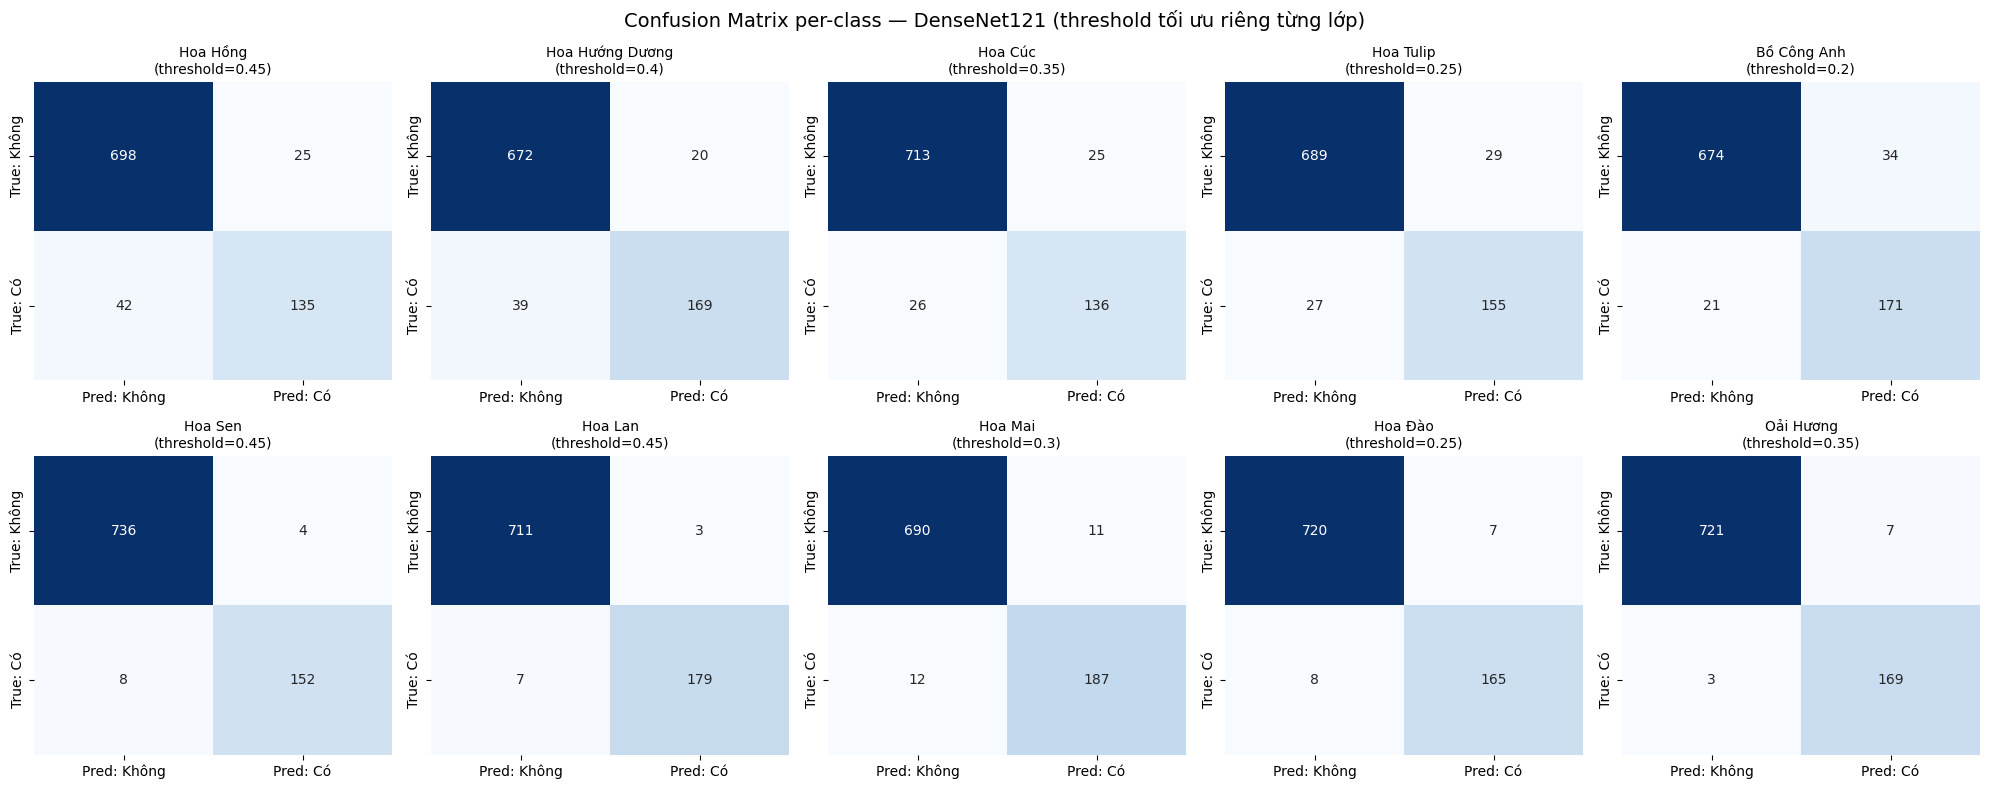

Đã lưu: /content/drive/MyDrive/flower-multilabel-project/reports/weekly_progress/tuan4_confusion_matrix_optimized.png
{
  "models": [
    {
      "id": "mobilenetv2",
      "name": "MobileNetV2",
      "val_accuracy": 0.9495555555555556,
      "val_auc": 0.9779694080352783,
      "precision": 0.9206447601318359,
      "recall": 0.8199889659881592,
      "is_selected": false
    },
    {
      "id": "mobilenetv3large",
      "name": "MobileNetV3Large",
      "val_accuracy": 0.9534444444444444,
      "val_auc": 0.9822262525558472,
      "precision": 0.9350000023841858,
      "recall": 0.8260629773139954,
      "is_selected": false
    },
    {
      "id": "efficientnetb0",
      "name": "EfficientNetB0",
      "val_accuracy": 0.9564444444444444,
      "val_auc": 0.9870618581771851,
      "precision": 0.9465072154998779,
      "recall": 0.8304803967475891,
      "is_selected": false
    },
    {
      "id": "resnet50v2",
      "name": "ResNet50V2",
      "val_accuracy": 0.954,
      "val_

In [19]:
# ---- 6.1: Vẽ lại confusion matrix per-class với threshold tối ưu (bản chính thức cho báo cáo) ----
mcm_opt = multilabel_confusion_matrix(y_true, y_pred_binary_opt)

fig, axes = plt.subplots(2, 5, figsize=(20, 8))
axes = axes.flatten()
for i, (cm, name) in enumerate(zip(mcm_opt, class_names)):
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues", cbar=False,
        xticklabels=["Pred: Không", "Pred: Có"],
        yticklabels=["True: Không", "True: Có"],
        ax=axes[i]
    )
    axes[i].set_title(f"{name}\n(threshold={optimal_thresholds[class_ids[i]]})", fontsize=10)

plt.suptitle("Confusion Matrix per-class — DenseNet121 (threshold tối ưu riêng từng lớp)", fontsize=14)
plt.tight_layout()

SAVE_PATH_OPT = f"{BASE_DIR}/reports/weekly_progress/tuan4_confusion_matrix_optimized.png"
plt.savefig(SAVE_PATH_OPT, dpi=150, bbox_inches="tight")
plt.show()
print(f"Đã lưu: {SAVE_PATH_OPT}")

# ---- 6.2: Cập nhật model_comparison.json — thêm thông tin đánh giá chi tiết của model được chọn ----
COMPARISON_PATH = f"{BASE_DIR}/models/comparison/model_comparison.json"
with open(COMPARISON_PATH, "r", encoding="utf-8") as f:
    comparison_data = json.load(f)

# In ra để xem cấu trúc hiện tại trước khi sửa (tránh đoán sai key)
print(json.dumps(comparison_data, ensure_ascii=False, indent=2))

In [20]:
# ---- 6.2 (tiếp): Cập nhật riêng entry densenet121 với kết quả đánh giá per-class + threshold tối ưu ----
for m in comparison_data["models"]:
    if m["id"] == "densenet121":
        m["precision_optimized"] = round(float(precision_macro_opt), 4)
        m["recall_optimized"] = round(float(recall_macro_opt), 4)
        m["f1_macro_optimized"] = round(float(f1_macro_opt), 4)
        m["f1_macro_default_threshold"] = round(float(f1_macro), 4)
        m["hamming_accuracy_optimized"] = round(float(hamming_acc_opt), 4)
        m["subset_accuracy_optimized"] = round(float(subset_acc_opt), 4)
        m["per_class_thresholds"] = optimal_thresholds
        m["per_class_f1_optimized"] = {
            cls_id: round(float(f1_opt[i]), 4) for i, cls_id in enumerate(class_ids)
        }

# ---- Lưu đè lại model_comparison.json gốc (models/comparison/) ----
with open(COMPARISON_PATH, "w", encoding="utf-8") as f:
    json.dump(comparison_data, f, ensure_ascii=False, indent=2)
print(f"Đã cập nhật: {COMPARISON_PATH}")

# ---- 6.3: Tạo thư mục backend/ (nếu chưa có) và copy model_comparison.json sang, đúng cấu trúc blueprint mục 3 ----
import os, shutil

BACKEND_DIR = f"{BASE_DIR}/backend"
os.makedirs(BACKEND_DIR, exist_ok=True)

shutil.copy(COMPARISON_PATH, f"{BACKEND_DIR}/model_comparison.json")
print(f"Đã copy sang: {BACKEND_DIR}/model_comparison.json")

# ---- 6.4: Copy thresholds.json sang backend/ để predict.py dùng ----
shutil.copy(THRESHOLDS_PATH, f"{BACKEND_DIR}/thresholds.json")
print(f"Đã copy sang: {BACKEND_DIR}/thresholds.json")

# ---- 6.5: Kiểm tra model cuối đã có sẵn chưa (đã xuất từ tuần 3, chỉ xác nhận lại) ----
if os.path.exists(MODEL_PATH):
    print(f"Model cuối đã sẵn sàng tại: {MODEL_PATH}")
else:
    print("⚠️ CHƯA thấy model tại models/final/ — cần export lại từ notebook 03.")

Đã cập nhật: /content/drive/MyDrive/flower-multilabel-project/models/comparison/model_comparison.json
Đã copy sang: /content/drive/MyDrive/flower-multilabel-project/backend/model_comparison.json
Đã copy sang: /content/drive/MyDrive/flower-multilabel-project/backend/thresholds.json
Model cuối đã sẵn sàng tại: /content/drive/MyDrive/flower-multilabel-project/models/final/flower_multilabel_model.keras


In [21]:
import json

BACKEND_DIR = f"{BASE_DIR}/backend"

care_guide = {
    "hoa_hong": {
        "anh_sang": "Cần ánh sáng mặt trời trực tiếp ít nhất 6 giờ/ngày, nên trồng ở nơi thoáng đãng.",
        "nuoc_tuoi": "Tưới 1 lần/ngày vào buổi sáng sớm, tránh tưới lên lá vào buổi tối để hạn chế nấm bệnh.",
        "dat_trong": "Đất tơi xốp, giàu dinh dưỡng, thoát nước tốt, pH 6.0-6.5.",
        "nhiet_do": "Thích hợp 18-25°C, chịu nóng kém khi trên 35°C.",
        "luu_y": "Cắt tỉa cành già, hoa tàn thường xuyên để kích thích ra hoa mới; dễ bị rệp và nấm đốm đen."
    },
    "hoa_huong_duong": {
        "anh_sang": "Ưa nắng gắt, cần tối thiểu 6-8 giờ ánh sáng trực tiếp mỗi ngày.",
        "nuoc_tuoi": "Tưới đều đặn 2-3 lần/tuần, tăng tần suất khi cây ra hoa và thời tiết khô nóng.",
        "dat_trong": "Đất thịt pha cát, thoát nước tốt, giàu mùn.",
        "nhiet_do": "Phát triển tốt ở 20-30°C, chịu nóng tốt hơn chịu lạnh.",
        "luu_y": "Cần cắm cọc hỗ trợ khi cây cao để tránh gãy đổ do gió; tránh trồng nơi ngập úng."
    },
    "hoa_cuc": {
        "anh_sang": "Ưa sáng, cần 5-6 giờ nắng trực tiếp/ngày, tránh nắng gắt buổi trưa nếu khí hậu quá nóng.",
        "nuoc_tuoi": "Giữ ẩm đều đặn, tưới 3-4 lần/tuần, tránh để đất khô hoàn toàn hoặc úng nước.",
        "dat_trong": "Đất giàu hữu cơ, tơi xốp, thoát nước tốt, pH 6.0-6.8.",
        "nhiet_do": "Thích hợp 18-24°C, ra hoa đẹp nhất khi biên độ ngày đêm không quá lớn.",
        "luu_y": "Ngắt ngọn khi cây còn nhỏ để cây phân nhánh nhiều, cho nhiều hoa hơn; dễ bị rệp và nấm phấn trắng."
    },
    "hoa_tulip": {
        "anh_sang": "Cần ánh sáng đầy đủ nhưng dịu, tránh nắng gắt trực tiếp giữa trưa.",
        "nuoc_tuoi": "Tưới vừa phải khi đất mặt se khô, tránh tưới quá nhiều gây thối củ.",
        "dat_trong": "Đất thoát nước cực tốt, tơi xốp, giàu dinh dưỡng, pH 6.0-7.0.",
        "nhiet_do": "Ưa mát, thích hợp 10-20°C; cần giai đoạn lạnh (dưới 10°C) để kích thích ra hoa.",
        "luu_y": "Củ tulip cần được bảo quản lạnh trước khi trồng; không trồng lại cùng một chỗ đất liên tục nhiều năm."
    },
    "hoa_bo_cong_anh": {
        "anh_sang": "Chịu được cả nắng gắt lẫn bóng râm nhẹ, phát triển tốt nhất khi có nắng trực tiếp.",
        "nuoc_tuoi": "Khá chịu hạn, chỉ cần tưới khi đất khô, không cần tưới thường xuyên.",
        "dat_trong": "Không kén đất, phát triển được cả ở đất nghèo dinh dưỡng, thoát nước trung bình.",
        "nhiet_do": "Chịu được biên độ nhiệt rộng, thích hợp 15-28°C.",
        "luu_y": "Sinh trưởng và lan rất nhanh, cần kiểm soát nếu không muốn cây mọc lan ra khu vực khác."
    },
    "hoa_sen": {
        "anh_sang": "Cần nắng trực tiếp toàn phần, tối thiểu 6 giờ/ngày để ra hoa.",
        "nuoc_tuoi": "Trồng trong nước, mực nước duy trì 15-30cm trên bề mặt bùn, không để cạn nước.",
        "dat_trong": "Bùn ao giàu dinh dưỡng hoặc đất sét nặng, ngập nước hoàn toàn.",
        "nhiet_do": "Ưa nóng ẩm, thích hợp 23-30°C, ngừng phát triển khi dưới 15°C.",
        "luu_y": "Không trồng chung chậu với cây cạn; cần bón phân định kỳ vào bùn để hoa to và bền."
    },
    "hoa_lan": {
        "anh_sang": "Ưa sáng nhưng tránh nắng trực tiếp gay gắt, thích hợp ánh sáng tán xạ 50-70%.",
        "nuoc_tuoi": "Tưới khi giá thể se khô, khoảng 2-3 lần/tuần, tránh đọng nước ở gốc và nách lá.",
        "dat_trong": "Giá thể thoáng khí: vỏ thông, than củi, dớn, xơ dừa — không dùng đất thịt thông thường.",
        "nhiet_do": "Thích hợp 20-28°C ban ngày, giảm nhẹ về đêm; nhạy cảm với thay đổi nhiệt độ đột ngột.",
        "luu_y": "Cần độ ẩm không khí cao (50-80%), thông thoáng tốt; dễ bị thối rễ nếu tưới quá nhiều."
    },
    "hoa_mai": {
        "anh_sang": "Cần nắng trực tiếp nhiều, tối thiểu 6 giờ/ngày, thiếu nắng cây sẽ ít hoa.",
        "nuoc_tuoi": "Tưới đều 1 lần/ngày mùa khô, giảm tưới mùa mưa; kiểm soát nước để canh hoa nở đúng Tết.",
        "dat_trong": "Đất pha cát hoặc đất thịt nhẹ, thoát nước tốt, không chịu được ngập úng.",
        "nhiet_do": "Thích hợp khí hậu nhiệt đới 25-30°C, chịu lạnh kém.",
        "luu_y": "Cần lặt lá đúng thời điểm (khoảng rằm tháng Chạp) để hoa nở đúng dịp Tết; bón phân định kỳ sau Tết để cây phục hồi."
    },
    "hoa_dao": {
        "anh_sang": "Cần nhiều ánh sáng trực tiếp, tối thiểu 6 giờ/ngày.",
        "nuoc_tuoi": "Tưới vừa phải 2-3 lần/tuần, tránh úng nước làm thối rễ.",
        "dat_trong": "Đất thịt pha cát, giàu dinh dưỡng, thoát nước tốt, hơi chua nhẹ (pH 5.5-6.5).",
        "nhiet_do": "Ưa khí hậu lạnh mát để phân hóa mầm hoa, thích hợp 15-25°C.",
        "luu_y": "Cần tuốt lá trước Tết khoảng 1 tháng để kích thích ra hoa đồng loạt; dễ bị sâu đục thân nếu không kiểm tra định kỳ."
    },
    "hoa_oai_huong": {
        "anh_sang": "Ưa nắng toàn phần, cần tối thiểu 6-8 giờ ánh sáng trực tiếp/ngày.",
        "nuoc_tuoi": "Chịu hạn tốt, chỉ tưới khi đất khô hẳn, tránh tưới quá nhiều gây úng rễ.",
        "dat_trong": "Đất thoát nước cực tốt, hơi kiềm (pH 6.5-7.5), không ưa đất ẩm ướt lâu ngày.",
        "nhiet_do": "Ưa khí hậu mát khô, thích hợp 15-25°C, không chịu được nóng ẩm kéo dài.",
        "luu_y": "Cần cắt tỉa sau mỗi đợt hoa tàn để cây không bị gỗ hóa; thông thoáng gió tốt để tránh nấm bệnh."
    }
}

# ---- Kiểm tra đủ 10 loại, mỗi loại đủ 5 trường (đúng CON-11) ----
required_fields = {"anh_sang", "nuoc_tuoi", "dat_trong", "nhiet_do", "luu_y"}
assert len(care_guide) == 10, f"Thiếu loại hoa, hiện có {len(care_guide)}/10"
for cls_id, fields in care_guide.items():
    assert set(fields.keys()) == required_fields, f"{cls_id} thiếu/thừa trường"
    assert all(v.strip() for v in fields.values()), f"{cls_id} có trường rỗng"
    assert cls_id in class_ids, f"{cls_id} không khớp với classes.json"

CARE_GUIDE_PATH = f"{BACKEND_DIR}/care_guide.json"
with open(CARE_GUIDE_PATH, "w", encoding="utf-8") as f:
    json.dump(care_guide, f, ensure_ascii=False, indent=2)

print(f"Đã tạo: {CARE_GUIDE_PATH}")
print("Kiểm tra: đủ 10 loại, mỗi loại đủ 5 trường ✓")

Đã tạo: /content/drive/MyDrive/flower-multilabel-project/backend/care_guide.json
Kiểm tra: đủ 10 loại, mỗi loại đủ 5 trường ✓


In [22]:
%%writefile {BACKEND_DIR}/model_loader.py
import os
import json
import tensorflow as tf

# Thư mục gốc dự án tính từ vị trí file này (backend/ nằm ngay dưới project root)
# -> khi chạy `python app.py` từ máy cục bộ, không phụ thuộc vào nơi gọi lệnh
BACKEND_DIR = os.path.dirname(os.path.abspath(__file__))
PROJECT_ROOT = os.path.dirname(BACKEND_DIR)

MODEL_PATH = os.path.join(PROJECT_ROOT, "models", "final", "flower_multilabel_model.keras")
CLASSES_PATH = os.path.join(PROJECT_ROOT, "data", "metadata", "classes.json")
THRESHOLDS_PATH = os.path.join(BACKEND_DIR, "thresholds.json")
CARE_GUIDE_PATH = os.path.join(BACKEND_DIR, "care_guide.json")
COMPARISON_PATH = os.path.join(BACKEND_DIR, "model_comparison.json")

_model = None
_classes = None
_thresholds = None
_care_guide = None


def load_model():
    """Nạp mô hình DenseNet121 đã huấn luyện. Chỉ load 1 lần khi khởi động server (NFR-05)."""
    global _model
    if _model is None:
        if not os.path.exists(MODEL_PATH):
            raise FileNotFoundError(f"Không tìm thấy model tại: {MODEL_PATH}")
        _model = tf.keras.models.load_model(MODEL_PATH)
        print(f"[model_loader] Đã nạp model từ: {MODEL_PATH}")
    return _model


def get_classes():
    """Trả về danh sách 10 lớp theo đúng thứ tự cố định trong classes.json (CON-05)."""
    global _classes
    if _classes is None:
        if not os.path.exists(CLASSES_PATH):
            raise FileNotFoundError(f"Không tìm thấy classes.json tại: {CLASSES_PATH}")
        with open(CLASSES_PATH, "r", encoding="utf-8") as f:
            _classes = json.load(f)
    return _classes


def get_thresholds():
    """Trả về ngưỡng riêng từng lớp (FR-05, MR-08)."""
    global _thresholds
    if _thresholds is None:
        if not os.path.exists(THRESHOLDS_PATH):
            raise FileNotFoundError(f"Không tìm thấy thresholds.json tại: {THRESHOLDS_PATH}")
        with open(THRESHOLDS_PATH, "r", encoding="utf-8") as f:
            _thresholds = json.load(f)
    return _thresholds


def get_care_guide():
    """Trả về dữ liệu hướng dẫn chăm sóc, bắt buộc đủ 10 loại x 5 trường (CON-11).
    Thiếu dữ liệu là lỗi cấu hình (EF-05), không được trả care_guide rỗng/giả."""
    global _care_guide
    if _care_guide is None:
        if not os.path.exists(CARE_GUIDE_PATH):
            raise FileNotFoundError(f"Không tìm thấy care_guide.json tại: {CARE_GUIDE_PATH}")
        with open(CARE_GUIDE_PATH, "r", encoding="utf-8") as f:
            data = json.load(f)

        classes = get_classes()
        class_ids = [c["id"] for c in classes]
        required_fields = {"anh_sang", "nuoc_tuoi", "dat_trong", "nhiet_do", "luu_y"}
        for cls_id in class_ids:
            if cls_id not in data:
                raise ValueError(f"[EF-05] care_guide.json thiếu dữ liệu cho lớp: {cls_id}")
            fields = data[cls_id]
            if set(fields.keys()) != required_fields or not all(str(v).strip() for v in fields.values()):
                raise ValueError(f"[EF-05] care_guide.json thiếu/rỗng trường dữ liệu cho lớp: {cls_id}")

        _care_guide = data
    return _care_guide


def get_model_comparison():
    """Trả về nội dung model_comparison.json (FR-10). Thiếu file là lỗi cấu hình (EF-06)."""
    if not os.path.exists(COMPARISON_PATH):
        raise FileNotFoundError(f"[EF-06] Không tìm thấy model_comparison.json tại: {COMPARISON_PATH}")
    with open(COMPARISON_PATH, "r", encoding="utf-8") as f:
        return json.load(f)

Writing /content/drive/MyDrive/flower-multilabel-project/backend/model_loader.py


In [24]:
%%writefile {BACKEND_DIR}/predict.py
import io
import numpy as np
from PIL import Image

from model_loader import load_model, get_classes, get_thresholds, get_care_guide

IMG_SIZE = (224, 224)

# Định dạng ảnh được phép (FR-02)
ALLOWED_FORMATS = {"JPEG", "PNG"}


def validate_image(file_bytes):
    """Kiểm tra ảnh có đúng định dạng JPEG/PNG không (FR-02, EF-01).
    Trả về (is_valid, error_message)."""
    try:
        img = Image.open(io.BytesIO(file_bytes))
        img.verify()  # kiểm tra file có bị hỏng không
    except Exception:
        return False, "File không phải là ảnh hợp lệ hoặc đã bị hỏng."

    # Mở lại vì verify() làm "hỏng" object ảnh, không dùng lại được
    img = Image.open(io.BytesIO(file_bytes))
    if img.format not in ALLOWED_FORMATS:
        return False, f"Định dạng ảnh không được hỗ trợ ({img.format}). Chỉ chấp nhận JPEG hoặc PNG."

    return True, None


def preprocess_image(file_bytes):
    """Resize ảnh về 224x224x3, giữ nguyên thang pixel [0, 255] vì model đã tự chứa
    preprocess_input bên trong (đúng bài học rút ra ở notebook 04 — KHÔNG tự chuẩn hóa lần nữa,
    tránh lỗi 'preprocess 2 lần' đã gặp phải)."""
    img = Image.open(io.BytesIO(file_bytes)).convert("RGB")
    img = img.resize(IMG_SIZE)
    arr = np.array(img, dtype=np.float32)          # [224, 224, 3], giá trị [0, 255]
    arr = np.expand_dims(arr, axis=0)               # [1, 224, 224, 3] — thêm batch dimension
    return arr


def predict_flowers(file_bytes):
    """Luồng chính FR-04 -> FR-05 -> FR-06: suy luận -> áp ngưỡng riêng từng lớp -> ghép care_guide.
    Trả về danh sách dict, mỗi phần tử gồm id, name, confidence, care_guide (FR-07)."""
    model = load_model()
    classes = get_classes()
    thresholds = get_thresholds()
    care_guide_data = get_care_guide()

    input_tensor = preprocess_image(file_bytes)
    probs = model.predict(input_tensor, verbose=0)[0]  # shape (10,)

    detected = []
    for i, cls in enumerate(classes):
        cls_id = cls["id"]
        cls_name = cls["name"]
        threshold = thresholds.get(cls_id, 0.5)  # fallback 0.5 nếu thiếu, không nên xảy ra

        if probs[i] >= threshold:
            detected.append({
                "id": cls_id,
                "name": cls_name,
                "confidence": round(float(probs[i]), 4),
                "care_guide": care_guide_data[cls_id]  # đã validate đủ 5 trường ở model_loader
            })

    # Sắp theo confidence giảm dần cho dễ nhìn (không quy định trong SRS, chỉ là UX hợp lý)
    detected.sort(key=lambda x: x["confidence"], reverse=True)
    return detected

Writing /content/drive/MyDrive/flower-multilabel-project/backend/predict.py


In [26]:
%%writefile {BACKEND_DIR}/app.py
import os
import uuid
from flask import Flask, request, jsonify
from flask_cors import CORS
from werkzeug.exceptions import RequestEntityTooLarge

from predict import validate_image, predict_flowers
from model_loader import get_model_comparison, load_model

app = Flask(__name__)
CORS(app)  # cho phép frontend (chạy port khác, vd Live Server 5500) gọi API

BACKEND_DIR = os.path.dirname(os.path.abspath(__file__))
UPLOAD_DIR = os.path.join(BACKEND_DIR, "static", "uploads")
os.makedirs(UPLOAD_DIR, exist_ok=True)

# ---- NFR-07: giới hạn kích thước file tải lên. Chốt 8MB (trong khoảng 5-10MB SRS đề xuất) ----
MAX_FILE_SIZE_MB = 8
app.config["MAX_CONTENT_LENGTH"] = MAX_FILE_SIZE_MB * 1024 * 1024

ALLOWED_EXTENSIONS = {"jpg", "jpeg", "png"}


def allowed_extension(filename):
    return "." in filename and filename.rsplit(".", 1)[1].lower() in ALLOWED_EXTENSIONS


@app.errorhandler(RequestEntityTooLarge)
def handle_file_too_large(e):
    # EF-02: file vượt quá giới hạn kích thước -> từ chối, không gọi model
    return jsonify({"error": f"File vượt quá giới hạn {MAX_FILE_SIZE_MB}MB."}), 413


@app.route("/predict", methods=["POST"])
def predict():
    # FR-02 / EF-03: chưa chọn ảnh hoặc thiếu field 'image'
    if "image" not in request.files:
        return jsonify({"error": "Thiếu file ảnh. Vui lòng chọn một ảnh để tải lên."}), 400

    file = request.files["image"]
    if file.filename == "":
        return jsonify({"error": "Chưa chọn file ảnh nào."}), 400

    # FR-02 / EF-01: kiểm tra định dạng theo phần mở rộng trước (nhanh, rẻ)
    if not allowed_extension(file.filename):
        return jsonify({"error": "Định dạng file không được hỗ trợ. Chỉ chấp nhận JPEG hoặc PNG."}), 400

    file_bytes = file.read()

    # FR-02 / EF-01: kiểm tra thực sự là ảnh hợp lệ (không chỉ dựa vào đuôi file)
    is_valid, error_msg = validate_image(file_bytes)
    if not is_valid:
        return jsonify({"error": error_msg}), 400

    # 8.1: lưu tạm vào backend/static/uploads/, không lưu trữ lâu dài
    temp_filename = f"{uuid.uuid4().hex}_{file.filename}"
    temp_path = os.path.join(UPLOAD_DIR, temp_filename)
    with open(temp_path, "wb") as f:
        f.write(file_bytes)

    try:
        detected_flowers = predict_flowers(file_bytes)
    except FileNotFoundError as e:
        # model hoặc classes.json bị thiếu -> lỗi cấu hình hệ thống
        return jsonify({"error": f"Lỗi cấu hình hệ thống: {str(e)}"}), 500
    except ValueError as e:
        # EF-05: care_guide.json thiếu dữ liệu cho một lớp được phát hiện
        return jsonify({"error": f"Lỗi dữ liệu chăm sóc: {str(e)}"}), 500
    finally:
        # dọn file tạm ngay sau khi xử lý xong, không lưu lâu dài
        if os.path.exists(temp_path):
            os.remove(temp_path)

    # FR-08: không nhãn nào vượt ngưỡng -> danh sách rỗng kèm thông điệp, vẫn là response thành công
    if len(detected_flowers) == 0:
        return jsonify({
            "detected_flowers": [],
            "message": "Không nhận diện được loại hoa nào trong ảnh này, vui lòng thử ảnh khác."
        }), 200

    return jsonify({"detected_flowers": detected_flowers}), 200


@app.route("/models/comparison", methods=["GET"])
def models_comparison():
    try:
        data = get_model_comparison()
    except FileNotFoundError as e:
        # EF-06: model_comparison.json chưa tồn tại hoặc không đọc được
        return jsonify({"error": f"Chưa có dữ liệu so sánh mô hình: {str(e)}"}), 500

    return jsonify(data), 200


if __name__ == "__main__":
    print("Đang nạp model...")
    load_model()  # nạp model 1 lần khi khởi động server (NFR-05), không load lại mỗi request
    print("Model đã sẵn sàng. Khởi động server tại http://localhost:5000")
    app.run(host="0.0.0.0", port=5000, debug=False)

Writing /content/drive/MyDrive/flower-multilabel-project/backend/app.py


In [35]:
%%writefile {BACKEND_DIR}/requirements.txt
flask==3.1.3
flask-cors==6.0.5
tensorflow==2.20.0
pillow==11.3.0
numpy==2.1.3

Overwriting /content/drive/MyDrive/flower-multilabel-project/backend/requirements.txt
